# EIS sensitivity spectra: how each loss responds to operating conditions, and how aging changes that

Extends the Tier-1 analysis (`eis_analysis.ipynb`) to the partial sensitivity tests: pressure, temperature, stoichiometry and humidity, at 1.8 A/cm², at BoL and after 2300 h. It also builds impedance-derived features that join onto `steady_state` for the degradation model.

**Status**
- [x] **Reference-cell responses reproduce the paper's Fig. 11**: ORR and mass transport fall with pressure; both are lowest at 70 °C; mass transport falls steeply with stoichiometry; the membrane barely moves.
- [x] **The paper's headline claim is supported by a within-stack test**: aging steepens the low-pressure penalty on total loss. Whether it is "especially ORR" depends on how the arcs are split (Tier 1 yes, circuit fit no).
- [x] **Aging amplifies the outlet's sensitivity** to low stoichiometry and low pressure; the inlet barely changes.
- [x] **The temperature optimum is region-dependent** after aging: inlet/middle at 70 °C, outlet at 75 °C or above.
- [x] **Model features**: `steady_state_eis` attaches reference-cell and region features to all 27 sensitivity holds at 1.8 A/cm²; reference-cell total resistance tracks cell voltage across conditions (r ≈ −0.9).
- [ ] **Two stacks**: BoL variation spectra come from a different (fresh 8-cell) stack, so BoL-vs-2300 h comparisons use within-stack ratios, not absolute values.

**Run order:** `eis_parser.py` → `eis_tier1.py` → `steady_state.py` → `python eis_sensitivity.py` (builds `eis_sensitivity`, `steady_state_eis`) → this notebook.

In [1]:
import os, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from contextlib import closing
import eis_tier1 as t1
import eis_sensitivity as es

HERE = os.getcwd()
PROJECT_DIR = os.path.dirname(HERE)
DB_path = os.path.join(PROJECT_DIR, "cathode_degradation.db")
pd.set_option("display.width", 200)

def q(sql):
    with closing(sqlite3.connect(f"file:{DB_path}?mode=ro", uri=True)) as con:
        return pd.read_sql_query(sql, con)

tables = q("SELECT name FROM sqlite_master WHERE type='table'").name.tolist()
assert {"eis_sensitivity", "steady_state_eis"} <= set(tables), "run  python eis_sensitivity.py  first"
F = q("SELECT * FROM eis_sensitivity")
SJ = q("SELECT * FROM steady_state_eis")
PARS = ["Pressure", "Temperature", "Stoichiometry", "Humidity"]
UNIT = {"Pressure": "cathode outlet pressure (kPaG)", "Temperature": "coolant inlet (°C)",
        "Stoichiometry": "cathode stoichiometry", "Humidity": "cathode RH (%)"}
ORDER = ["1 inlet", "2 upper", "3 middle", "4 lower", "5 outlet"]
print("eis_sensitivity:", F.shape, "| steady_state_eis:", SJ.shape)

eis_sensitivity: (180, 12) | steady_state_eis: (27, 40)


## 1. Conventions: what the file labels mean

- **Pressure labels are absolute kPa.** The papers' Table 2 only spans 50/60 to 200/210 kPaG, so `p160` / `p1_160_150` = 50 kPaG at the cathode outlet (the lowest level), `p210` = 100 kPaG, `p310` = 200 kPaG. This also matches the paper's note that the lowest pressure could not be measured after aging: 2300 h has no `p160`.
- **Humidity level** = cathode RH referenced to 70 °C (nominal 35 %); in `steady_state` it is recovered from the dew point.
- **No variation set contains its nominal point.** The nominal spatial spectrum of the same age (504 A) is added as the anchor: for 2300 h it was recorded on 1 Aug 2025, the same day the 2300 h temperature sweep began.
- **Two stacks.** The BoL variation spectra were measured on a fresh 8-cell short stack in Oct–Nov 2025, after the durability test. The BoL nominal anchor (Jan 2025), all aged spectra, and all of `steady_state` come from the 10-cell durability stack. The stacks differ by ~13 % in HFR at BoL, so **compare BoL 8-cell values only within that stack** (ratios), never as absolute "before" values for the durability stack.

In [2]:
c = q("SELECT DISTINCT kind, measurement, age_h, condition, meas_date FROM eis_raw "
      "WHERE measurement != 'nominal' AND (kind='cell' OR tst_index=1)")
c["level"] = [es.eis_level(p, k) for p, k in zip(c.measurement, c.condition)]
c["stack"] = np.where(c.age_h == 0, "8-cell short stack (fresh)", "10-cell durability stack")
c.sort_values(["measurement", "age_h", "level", "kind"]).reset_index(drop=True)

,kind,measurement,age_h,condition,meas_date,level,stack
0,spatial,Humidity,0,RH1_30_30,"NOV,04.2025",30.0,8-cell short stack (fresh)
1,spatial,Humidity,0,RH2_70_60,"NOV,04.2025",60.0,8-cell short stack (fresh)
2,spatial,Humidity,0,RH3_90_90,"NOV,04.2025",90.0,8-cell short stack (fresh)
3,spatial,Humidity,2300,RH_30_30,"AUG,07.2025",30.0,10-cell durability stack
4,spatial,Humidity,2300,RH_70_60,"AUG,07.2025",60.0,10-cell durability stack
5,spatial,Humidity,2300,RH_90_90,"AUG,07.2025",90.0,10-cell durability stack
6,cell,Pressure,0,p160,"NOV,03.2025",50.0,8-cell short stack (fresh)
7,spatial,Pressure,0,p1_160_150,"NOV,03.2025",50.0,8-cell short stack (fresh)
8,cell,Pressure,0,p210,"NOV,03.2025",100.0,8-cell short stack (fresh)
9,spatial,Pressure,0,p2_210_200,"NOV,03.2025",100.0,8-cell short stack (fresh)


## 2. Reference cell: response of each loss to operating conditions

Tier-1 values of the reference-cell spectrum (HFR = Z′ at 1 kHz, ORR = IFR − HFR, MT = LFR − IFR, LFR = total), in mΩ cm². BoL 8-cell values are dashed; the BoL nominal anchor from the 10-cell stack is marked ✕ and deliberately not connected. At 50 kPaG (BoL) the two arcs merge, so only HFR and LFR exist there.

In [3]:
cell = F[F.scope == "cell"]
cell.pivot_table(index=["parameter", "level"], columns="age_h", values=["HFR", "ORR", "MT", "LFR"]).round(1)

HFR          LFR           MT          ORR      
age_h                0     2300   0      2300  0      2300  0     2300
parameter     level                                                   
Humidity      35.0   54.2  59.1  184.3  200.1  65.9   71.2  64.2  69.8
Pressure      50.0   53.9   NaN  306.1    NaN   NaN    NaN   NaN   NaN
              100.0  49.1  60.2  231.6  257.3  92.8  103.2  89.7  93.9
              150.0  54.2  59.1  184.3  200.1  65.9   71.2  64.2  69.8
              200.0  47.0  58.0  182.9  188.9  65.3   67.0  70.6  63.9
Stoichiometry 1.6    46.7  58.1  218.7  236.3  92.1  101.4  79.9  76.8
              1.7    54.2  59.1  184.3  200.1  65.9   71.2  64.2  69.8
              2.1    47.9  60.0  159.2  171.9  42.6   46.0  68.7  66.0
Temperature   55.0   46.8  60.6  216.4  232.8  79.6   82.1  90.0  90.1
              60.0   46.3  59.4  206.4  214.7  77.4   75.8  82.8  79.5
              65.0   46.1  59.0  201.0  210.4  75.7   75.8  79.3  75.6
              70.0   54.2  59.1  184.3  200.1  65.9   71.2  64.2  69.8
              75.0   46.8  59.2  203.6  212.8  79.4   79.2  77.3  74.4

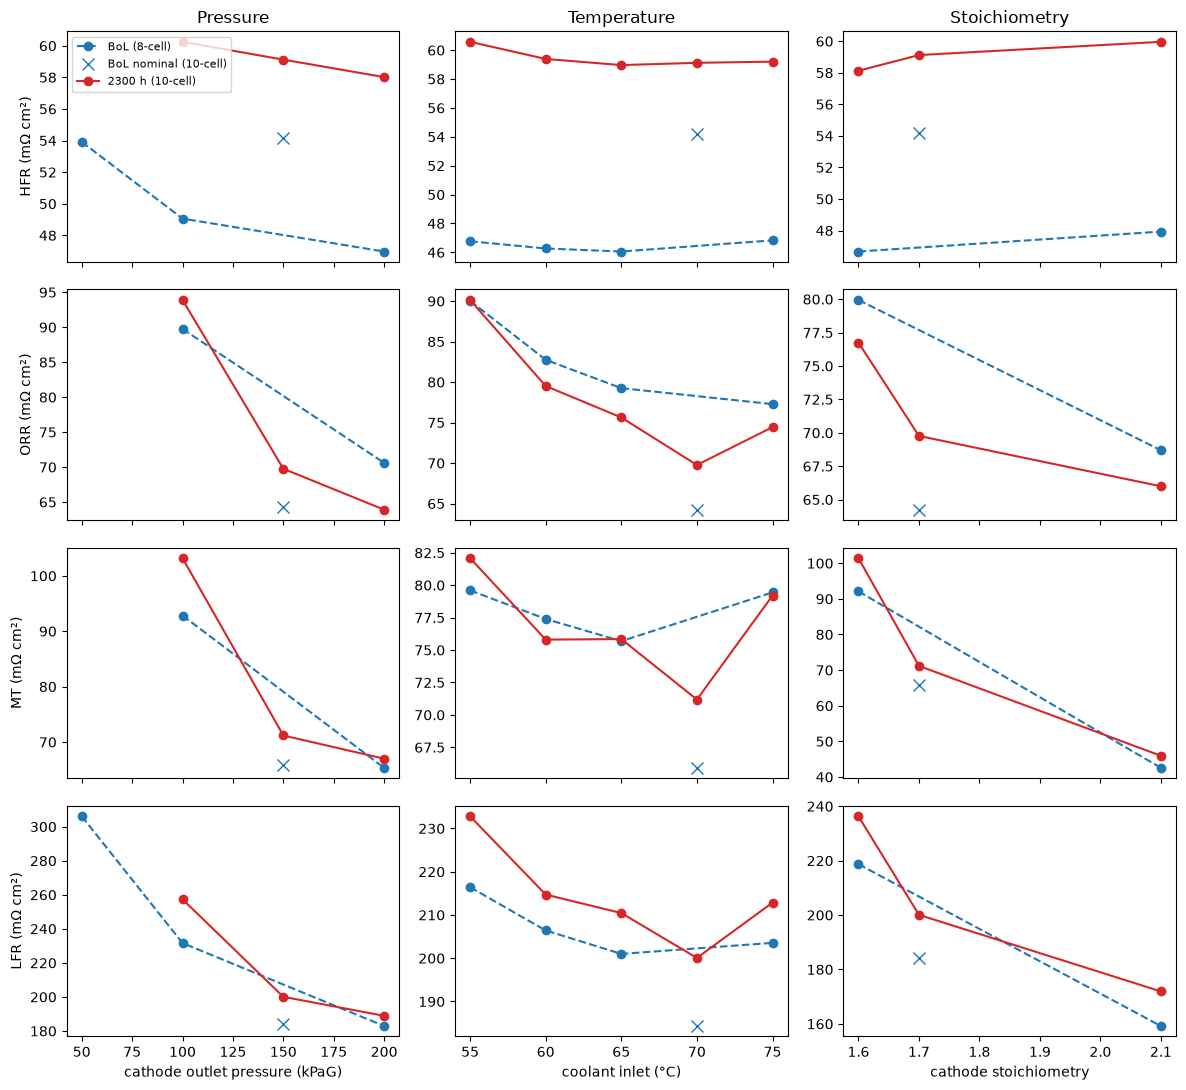

In [4]:
fig, axs = plt.subplots(4, 3, figsize=(12, 11), sharex="col")
for j, par in enumerate(["Pressure", "Temperature", "Stoichiometry"]):
    for i, m in enumerate(["HFR", "ORR", "MT", "LFR"]):
        ax = axs[i, j]
        for age in (0, 2300):
            d = cell[(cell.parameter == par) & (cell.age_h == age)].sort_values("level")
            if age == 0:
                v, a = d[d.is_nominal == 0], d[d.is_nominal == 1]
                ax.plot(v.level, v[m], "o--", color="C0", label="BoL (8-cell)")
                ax.plot(a.level, a[m], "x", color="C0", ms=9, label="BoL nominal (10-cell)")
            else:
                ax.plot(d.level, d[m], "o-", color="C3", label="2300 h (10-cell)")
        if i == 0: ax.set_title(par)
        if j == 0: ax.set_ylabel(f"{m} (mΩ cm²)")
        if i == 3: ax.set_xlabel(UNIT[par])
axs[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Within-stack test of the paper's headline claim

The abstract states that the degradation impact increases with decreasing pressure, especially in the ORR resistance. Comparing absolute BoL and 2300 h values would mix aging with the stack-to-stack offset. Instead, each stack's **own** low/high ratio is compared: if aging makes low pressure (or low stoichiometry, or a temperature away from the optimum) more harmful, the ratio grows from BoL to 2300 h. A uniform offset between the stacks cancels in the ratio.

In [5]:
def ratio(df, par, lo, hi, cols=("HFR", "ORR", "MT", "LFR"), scope="cell"):
    d = df[(df.scope == scope) & (df.parameter == par)]
    out = {}
    for age in (0, 2300):
        g = d[d.age_h == age].set_index("level")
        if lo in g.index and hi in g.index:
            out[age] = {col: g.loc[lo, col] / g.loc[hi, col] for col in cols}
    return pd.DataFrame(out).T

pen = pd.concat({"pressure 100/200 kPaG": ratio(F, "Pressure", 100.0, 200.0),
                 "stoich 1.6/2.1": ratio(F, "Stoichiometry", 1.6, 2.1),
                 "temperature 55/65 °C": ratio(F, "Temperature", 55.0, 65.0)},
                names=["penalty (reference cell)", "age_h"])
pen.round(2)

HFR   ORR    MT   LFR
penalty (reference cell) age_h                        
pressure 100/200 kPaG    0      1.04  1.27  1.42  1.27
                         2300   1.04  1.47  1.54  1.36
stoich 1.6/2.1           0      0.97  1.16  2.16  1.37
                         2300   0.97  1.16  2.21  1.37
temperature 55/65 °C     0      1.02  1.14  1.05  1.08
                         2300   1.03  1.19  1.08  1.11

## 3. Seeded circuit fit for each condition (reference cell)

The same R0 + two R-CPE circuit as in `eis_analysis.ipynb`, fitted with `impedance.py` from Tier-1 starting values, gives a fit-based decomposition at every condition. Spectra without a valley (BoL, 50 kPaG) return no fit.

In [6]:
from impedance.models.circuits import CustomCircuit

def spectrum(where):
    d = q(f"SELECT frequency_Hz AS f, Zreal_Ohm AS zr, Zimag_Ohm AS zi FROM eis_raw WHERE {where}")
    d["fr"] = d.f.round(1)
    g = d.groupby("fr").agg(f=("f", "mean"), zr=("zr", "mean"), zi=("zi", "mean")).sort_values("f")
    return g.f.values, g.zr.values, g.zi.values

def fit_seeded(f, zr, zi, fmax=t1.FMAX_CELL):
    r = t1.tier1(f, zr, zi, fmax)
    fs, zrs, nz = t1._prep(f, zr, zi, fmax)
    i_orr = t1._first_peak(nz)
    half = len(nz) // 2
    i_mt = half + int(np.argmax(nz[half:]))
    R0 = r["HFR_ext"] if np.isfinite(r["HFR_ext"]) else (r["HFR_1k"] if np.isfinite(r["HFR_1k"]) else zrs.min())
    R1, R2, a = r["IFR"] - R0, r["LFR"] - r["IFR"], 0.85
    if not (np.isfinite(R1) and R1 > 0 and R2 > 0):
        return None
    Q1, Q2 = 1 / (R1 * (2*np.pi*fs[i_orr])**a), 1 / (R2 * (2*np.pi*fs[i_mt])**a)
    o = np.argsort(fs)
    ff, Z = fs[o], (zrs - 1j*nz)[o]
    circ = CustomCircuit("R0-p(R1,CPE1)-p(R2,CPE2)", initial_guess=[R0, R1, Q1, a, R2, Q2, a])
    circ.fit(ff, Z)
    p = circ.parameters_
    tau1, tau2 = (p[1]*p[2])**(1/p[3]), (p[4]*p[5])**(1/p[6])
    R_orr, R_mt = (p[1], p[4]) if tau1 <= tau2 else (p[4], p[1])
    rms = np.sqrt((np.abs(circ.predict(ff) - Z)**2).mean()) / np.abs(Z).mean()
    return {"R0_fit": p[0], "ORR_fit": R_orr, "MT_fit": R_mt, "rms": rms}

K = t1.CELL_AREA_CM2 * 1e3
rows = []
conds = q("SELECT DISTINCT age_h, measurement, condition FROM eis_raw WHERE kind='cell' AND measurement != 'nominal'")
for _, r in conds.iterrows():
    s = fit_seeded(*spectrum(f"kind='cell' AND measurement='{r.measurement}' "
                             f"AND condition='{r.condition}' AND age_h={r.age_h}"))
    if s:
        rows.append({"age_h": r.age_h, "parameter": r.measurement, "level": es.eis_level(r.measurement, r.condition),
                     **{k: (v if k == "rms" else v * K) for k, v in s.items()}})
for age in (0, 2300):
    s = fit_seeded(*spectrum("kind='spatial' AND is_reference=1 AND measurement='nominal' "
                             f"AND ROUND(dc_current_A)=505 AND age_h={age}"))
    rows.append({"age_h": age, "parameter": "nominal anchor", "level": np.nan,
                 **{k: (v if k == "rms" else v * K) for k, v in s.items()}})
fits = pd.DataFrame(rows).sort_values(["parameter", "age_h", "level"]).reset_index(drop=True)
print("max fit rms:", round(fits.rms.max(), 4))
fits.round(2)

max fit rms: 0.0452


,age_h,parameter,level,R0_fit,ORR_fit,MT_fit,rms
0,0,Pressure,100.0,51.33,80.99,97.30,0.02
1,0,Pressure,200.0,49.78,62.29,70.85,0.03
2,2300,Pressure,100.0,41.36,111.50,101.75,0.02
3,2300,Pressure,200.0,36.92,83.83,68.72,0.02
4,0,Stoichiometry,1.6,44.34,75.31,101.60,0.05
5,0,Stoichiometry,2.1,46.03,68.03,47.27,0.04
6,2300,Stoichiometry,1.6,40.42,94.88,98.77,0.02
7,2300,Stoichiometry,2.1,38.27,86.89,47.26,0.02
8,0,Temperature,55.0,49.02,80.86,87.60,0.03
9,0,Temperature,60.0,49.07,73.30,83.76,0.03


### Does the circuit fit agree on the pressure penalty?

The same within-stack ratio, computed from the fitted resistances. LFR does not depend on the decomposition, so it is the robust measure; ORR and MT depend on how the fit splits the two arcs.

In [7]:
fr = {}
for age in (0, 2300):
    g = fits[(fits.parameter == "Pressure") & (fits.age_h == age)].set_index("level")
    fr[age] = {f"{m} (fit)": g.loc[100.0, f"{m}_fit"] / g.loc[200.0, f"{m}_fit"] for m in ("R0", "ORR", "MT")}
pd.concat([pd.DataFrame(fr).T, pen.loc["pressure 100/200 kPaG"].add_suffix(" (Tier 1)")], axis=1).round(2)

,R0 (fit),ORR (fit),MT (fit),HFR (Tier 1),ORR (Tier 1),MT (Tier 1),LFR (Tier 1)
0,1.03,1.30,1.37,1.04,1.27,1.42,1.27
2300,1.12,1.33,1.48,1.04,1.47,1.54,1.36


Both methods agree that aging steepens the low-pressure penalty. They disagree on where it sits: Tier 1 puts most of the increase in ORR (1.27 → 1.47), while the fit puts it mostly in mass transport (MT 1.37 → 1.48, ORR 1.30 → 1.33). At 100 kPaG after aging the two arcs overlap strongly, so the split is not well determined. **The robust statement is the total-loss penalty (LFR 1.27 → 1.36); "especially ORR" holds in Tier 1 but not in the fit.** The fitted R0 is ~15 mΩ cm² below HFR_1k because the first CPE absorbs the high-frequency proton-transport part of the catalyst layer; that offset is the same across conditions.

## 4. Where: region profiles along the cathode flow (cf. the paper's Fig. 12)

Each line is one operating level, plotted from the cathode inlet to the outlet (zone impedance × zone area, mΩ cm²). The nominal anchor is the dashed black line; at BoL it comes from the 10-cell stack.

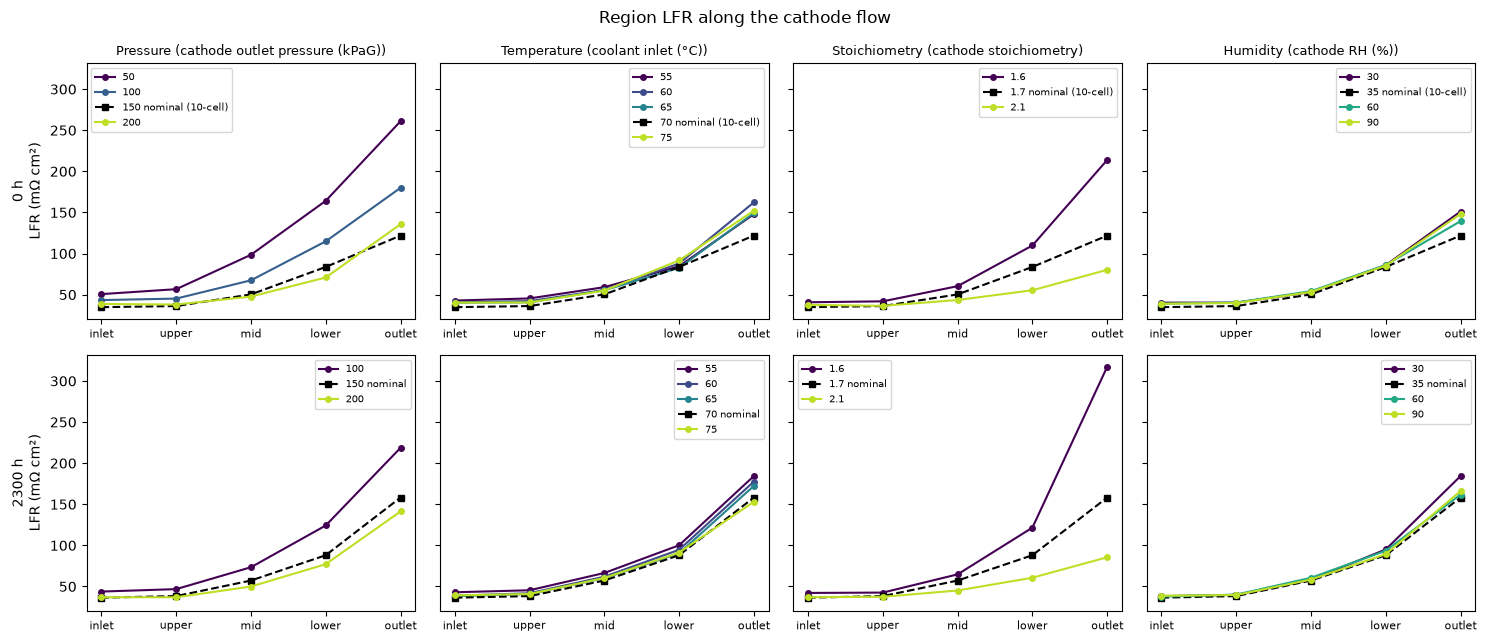

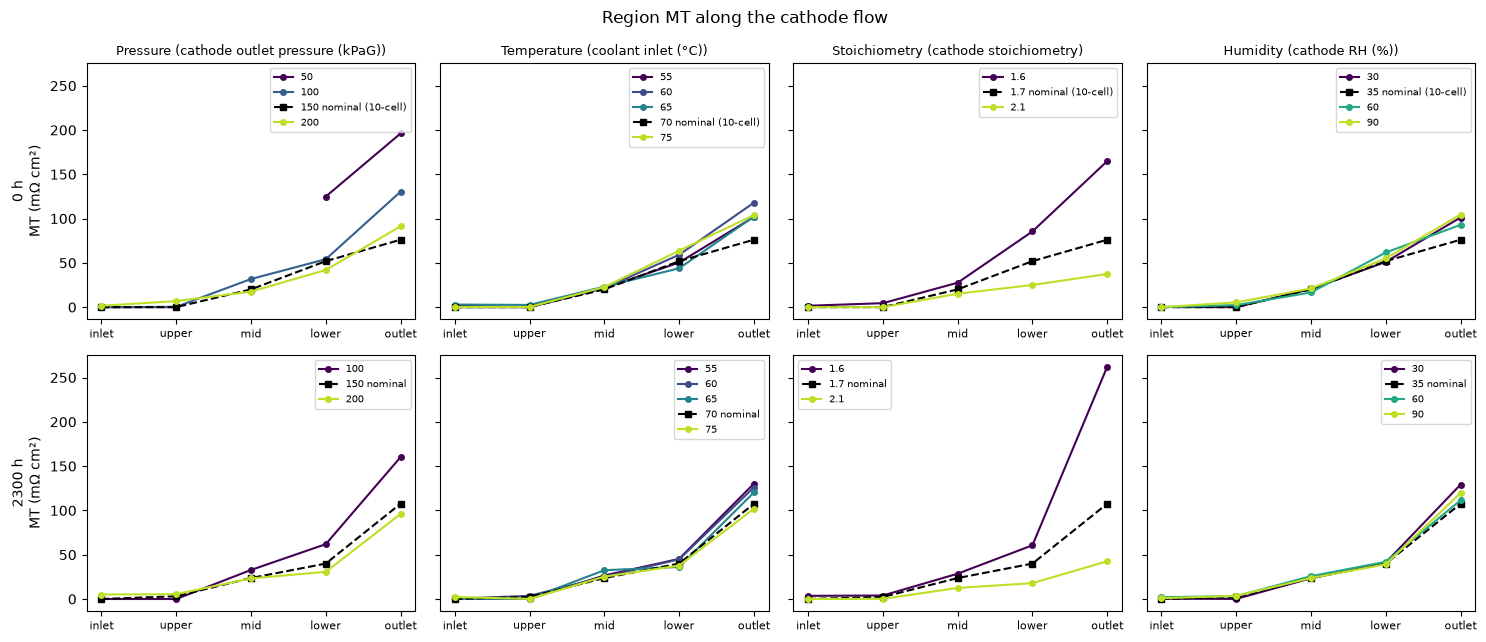

In [8]:
reg = F[F.scope != "cell"]
for metric in ("LFR", "MT"):
    fig, axs = plt.subplots(2, 4, figsize=(15, 6.5), sharey=True)
    for i, age in enumerate((0, 2300)):
        for j, par in enumerate(PARS):
            ax = axs[i, j]
            d = reg[(reg.parameter == par) & (reg.age_h == age)]
            levels = sorted(d.level.unique())
            colors = plt.cm.viridis(np.linspace(0, 0.9, len(levels)))
            for lv, col in zip(levels, colors):
                g = d[d.level == lv].set_index("scope").reindex(ORDER)
                if g.is_nominal.max() == 1:
                    ax.plot(range(5), g[metric], "--", color="k", marker="s", ms=4,
                            label=f"{lv:g} nominal" + (" (10-cell)" if age == 0 else ""))
                else:
                    ax.plot(range(5), g[metric], "-", color=col, marker="o", ms=4, label=f"{lv:g}")
            ax.set_xticks(range(5)); ax.set_xticklabels(["inlet", "upper", "mid", "lower", "outlet"], fontsize=8)
            if i == 0: ax.set_title(f"{par} ({UNIT[par]})", fontsize=9)
            if j == 0: ax.set_ylabel(f"{age} h\n{metric} (mΩ cm²)")
            ax.legend(fontsize=7)
    fig.suptitle(f"Region {metric} along the cathode flow")
    plt.tight_layout(); plt.show()

### Aging amplifies the outlet's sensitivity

The same within-stack ratio as above, applied to the outlet and inlet regions (total loss, LFR).

In [9]:
TESTS = {"stoich 1.6/2.1": ("Stoichiometry", 1.6, 2.1), "pressure 100/200": ("Pressure", 100.0, 200.0),
         "humidity 30/60": ("Humidity", 30.0, 60.0), "temperature 55/65": ("Temperature", 55.0, 65.0)}

def pen_table(scope, metric="LFR"):
    return pd.concat({k: ratio(F, p, lo, hi, (metric,), scope)[metric] for k, (p, lo, hi) in TESTS.items()}, axis=1)

pd.concat({"outlet LFR ratio": pen_table("5 outlet"), "outlet MT ratio": pen_table("5 outlet", "MT"),
           "inlet LFR ratio": pen_table("1 inlet")}, names=["", "age_h"]).round(2)

stoich 1.6/2.1  pressure 100/200  humidity 30/60  temperature 55/65
                 age_h                                                                     
outlet LFR ratio 0                2.67              1.33            1.08               0.99
                 2300             3.71              1.55            1.14               1.07
outlet MT ratio  0                4.40              1.43            1.09               1.00
                 2300             6.15              1.67            1.16               1.08
inlet LFR ratio  0                1.09              1.12            1.03               1.06
                 2300             1.14              1.19            1.01               1.13

### Temperature optimum by region (2300 h, same stack)

For each region, the temperature with the lowest measured loss, and the vertex of a quadratic fit through the five levels (`>75` when the loss is still falling at 75 °C).

In [10]:
rows = []
for scope in ["cell"] + ORDER:
    d = F[(F.parameter == "Temperature") & (F.age_h == 2300) & (F.scope == scope)].sort_values("level")
    rec = {"scope": scope}
    for m in ("LFR", "ORR", "MT"):
        x, y = d.level.values, d[m].values
        ok = np.isfinite(y)
        if ok.sum() < 4 or np.allclose(y[ok], 0):
            continue
        rec[f"{m} lowest at"] = x[ok][np.argmin(y[ok])]
        a, b, _ = np.polyfit(x[ok], y[ok], 2)
        v = -b / (2*a) if a > 0 else np.inf
        rec[f"{m} quad. vertex"] = ">75" if v > 75 else ("<55" if v < 55 else round(v, 1))
    rows.append(rec)
pd.DataFrame(rows).set_index("scope")

,LFR lowest at,LFR quad. vertex,ORR lowest at,ORR quad. vertex,MT lowest at,MT quad. vertex
scope,,,,,,
cell,70.0,68.4,70.0,70.0,70.0,66.5
1 inlet,70.0,67.7,75.0,>75,55.0,61.5
2 upper,70.0,69.0,70.0,67.8,75.0,>75
3 middle,70.0,69.1,65.0,66.5,70.0,>75
4 lower,70.0,69.4,70.0,65.4,65.0,72.8
5 outlet,75.0,>75,70.0,71.2,75.0,>75


## 5. Features for the degradation model: `steady_state_eis`

Each `steady_state` sensitivity hold at ~1.8 A/cm² gets the impedance features of the matching (age, parameter, level):
- reference cell: `cell_HFR`, `cell_ORR`, `cell_MT`, `cell_LFR`
- regions: `outlet_LFR`, `outlet_MT`, `outlet_ORR`, `inlet_LFR`, `outlet_inlet_LFR`, `zone_LFR_CoV` (spatial heterogeneity of the loss)

`eis_same_stack = 1` when the features come from the 10-cell durability stack (all 2300 h rows, and the BoL nominal rows). Humidity has region features only, since no reference-cell humidity spectra exist.

In [11]:
show = ["age_h", "eis_parameter", "level", "is_nominal", "eis_same_stack", "U_avecell", "cell_HFR", "cell_ORR",
        "cell_MT", "cell_LFR", "outlet_LFR", "outlet_inlet_LFR", "zone_LFR_CoV"]
SJ[show].sort_values(["age_h", "eis_parameter", "level"]).round(3).reset_index(drop=True)

,age_h,eis_parameter,level,is_nominal,eis_same_stack,U_avecell,cell_HFR,cell_ORR,cell_MT,cell_LFR,outlet_LFR,outlet_inlet_LFR,zone_LFR_CoV
0,0,Humidity,30.0,0,0,0.615,NaN,NaN,NaN,NaN,151.099,3.749,0.594
1,0,Humidity,60.0,0,0,0.622,NaN,NaN,NaN,NaN,139.410,3.571,0.592
2,0,Humidity,90.0,0,0,0.630,NaN,NaN,NaN,NaN,148.199,3.806,0.640
3,0,Pressure,50.0,0,0,0.541,53.917,NaN,NaN,306.098,260.913,5.150,0.671
4,0,Pressure,100.0,0,0,0.594,49.062,89.747,92.838,231.648,179.956,4.146,0.616
5,0,Pressure,150.0,1,1,0.615,54.170,64.245,65.919,184.333,121.856,3.502,0.594
6,0,Pressure,200.0,0,0,0.636,46.978,70.609,65.344,182.932,135.663,3.504,0.579
7,0,Stoichiometry,1.6,0,0,0.615,46.671,79.941,92.100,218.713,213.859,5.249,0.751
8,0,Stoichiometry,1.7,1,1,0.618,54.170,64.245,65.919,184.333,121.856,3.502,0.594
9,0,Stoichiometry,2.1,0,0,0.627,47.934,68.695,42.571,159.201,80.222,2.138,0.340


Pearson r between cell voltage and each feature, across the sensitivity holds:


,2300 h (same stack),BoL
cell_LFR,-0.88,-0.94
cell_ORR,-0.92,-0.77
cell_MT,-0.74,-0.64
cell_HFR,-0.59,-0.41
outlet_LFR,-0.51,-0.77
outlet_inlet_LFR,-0.41,-0.58
zone_LFR_CoV,-0.34,-0.32


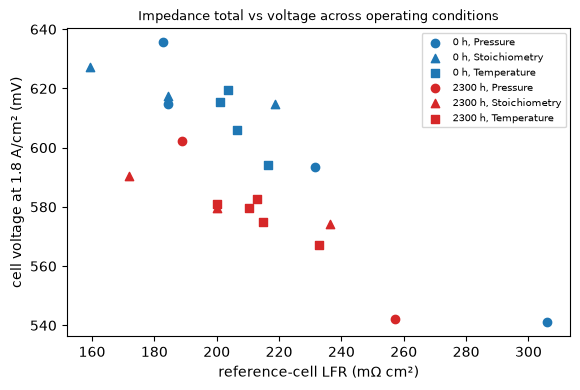

In [12]:
feat_cols = ["cell_LFR", "cell_ORR", "cell_MT", "cell_HFR", "outlet_LFR", "outlet_inlet_LFR", "zone_LFR_CoV"]
corr = pd.DataFrame({lab: {col: SJ.loc[m, ["U_avecell", col]].dropna().corr().iloc[0, 1] for col in feat_cols}
                     for lab, m in (("2300 h (same stack)", SJ.age_h == 2300), ("BoL", SJ.age_h == 0))})
print("Pearson r between cell voltage and each feature, across the sensitivity holds:")
display(corr.round(2))

fig, ax = plt.subplots(figsize=(6.5, 4))
mk = {"Pressure": "o", "Temperature": "s", "Stoichiometry": "^"}
for (age, par), g in SJ.dropna(subset=["cell_LFR"]).groupby(["age_h", "eis_parameter"]):
    ax.scatter(g.cell_LFR, g.U_avecell * 1e3, marker=mk.get(par, "x"), color="C3" if age else "C0",
               label=f"{age} h, {par}")
ax.set_xlabel("reference-cell LFR (mΩ cm²)"); ax.set_ylabel("cell voltage at 1.8 A/cm² (mV)")
ax.set_title("Impedance total vs voltage across operating conditions", fontsize=9)
ax.legend(fontsize=7); plt.show()

### Sensitivity coefficients (for the operating-point optimizer)

Finite-difference slopes of each loss with respect to the two strongest levers, per stack and age. These are the quantities an optimizer or MPC needs: how much loss a pressure or air-flow increase buys back, and how that changes as the stack ages.

In [13]:
def slope(par, lo, hi, scope, m, age):
    g = F[(F.parameter == par) & (F.scope == scope) & (F.age_h == age)].set_index("level")[m]
    return (g.get(hi, np.nan) - g.get(lo, np.nan)) / (hi - lo)

coef = []
for age in (0, 2300):
    for scope in ("cell", "5 outlet"):
        for m in ("ORR", "MT", "LFR"):
            coef.append({"age_h": age, "scope": scope, "loss": m,
                         "Δ per +100 kPa (100→200 kPaG)": 100 * slope("Pressure", 100.0, 200.0, scope, m, age),
                         "Δ per +0.1 stoich (1.6→2.1)": 0.1 * slope("Stoichiometry", 1.6, 2.1, scope, m, age)})
pd.DataFrame(coef).set_index(["age_h", "scope", "loss"]).round(1)

Δ per +100 kPa (100→200 kPaG)  Δ per +0.1 stoich (1.6→2.1)
age_h scope    loss                                                            
0     cell     ORR                           -19.1                         -2.2
               MT                            -27.5                         -9.9
               LFR                           -48.7                        -11.9
      5 outlet ORR                            -4.7                         -1.4
               MT                            -39.1                        -25.5
               LFR                           -44.3                        -26.7
2300  cell     ORR                           -30.0                         -2.2
               MT                            -36.2                        -11.1
               LFR                           -68.4                        -12.9
      5 outlet ORR                           -12.9                         -2.7
               MT                            -64.1                        -43.9
               LFR                           -77.4                        -46.3

## 6. Findings vs the paper

| Claim | This work (Tier 1, see tables above) | Paper | |
|---|---|---|---|
| ORR and MT fall with pressure, both ages | 2300 h: ORR 94 → 70 → 64, MT 103 → 71 → 67 mΩ cm² (100/150/200 kPaG) | Fig. 11b | agree |
| Membrane vs pressure | slight drop at BoL (49 → 47), ~flat after aging (60 → 58) | slight decrease at BoL, stable after 2300 h | agree |
| ORR and MT minimal at 70 °C | 2300 h minimum at 70 °C for both | Fig. 11c | agree |
| Aging steepens the temperature penalty | ORR 55/65 °C ratio 1.14 → 1.19, MT 1.05 → 1.08 | steeper after aging | agree (modest) |
| Stoichiometry drives mass transport, mostly at the outlet; ORR falls; membrane flat | 2300 h MT 101 → 46; outlet LFR 317 → 86 | Fig. 11d, Fig. 12 | agree |
| "Degradation impact increases with decreasing pressure, especially ORR" | within-stack LFR(100)/LFR(200) 1.27 → 1.36; Tier-1 ORR 1.27 → 1.47, but the circuit fit puts the increase in MT (ORR 1.30 → 1.33) | abstract | total loss supported; "especially ORR" depends on the decomposition |
| Aging amplifies the outlet's sensitivity | outlet LFR stoich ratio 2.7 → 3.7, pressure ratio 1.33 → 1.55; inlet ~unchanged | qualitative in Fig. 12 | extends |
| Temperature optimum by region | after aging: inlet and middle lowest at 70 °C, outlet still falling at 75 °C | not reported | new |

**For the model.** Reference-cell total resistance tracks cell voltage across operating conditions (r ≈ −0.9), so `steady_state_eis` carries most of the voltage response at 1.8 A/cm² and splits it into membrane, ORR and mass-transport parts. The outlet features add what voltage hides: at 2300 h, stoichiometry moves the voltage by only ~16 mV while the outlet loss changes 3.7×. Use `eis_same_stack == 1` rows when absolute values matter.

**Caveats.** One spectrum per condition (no repeats), so the ratios are indicative, without error bars. BoL variation spectra come from a different stack. No reference-cell humidity spectra. No 50 kPaG point after aging. EIS exists only at 1.8 A/cm². The quality of the model is botherlining "Trust me" quality due to lack of experimental repeatition and thin data slices on a few opearting conditions like pressure data on HFR, LFR, MT, ORR at different timestamps.